# Background

In this notebook we'll explore  electrical impedance measurements of freshly excised tissue samples from the breast. The data is sourced from S, JP and Jossinet, J. (2010). Breast Tissue. UCI Machine Learning Repository. https://doi.org/10.24432/C5P31H

by way of https://www.kaggle.com/datasets/tarktunataalt/breast-tissue-impedance-measurements 

Impedance measurements were taken at the following frequencies: 15.625, 31.25, 62.5, 125, 250, 500, and 1000 KHz. These measurements, when plotted in the (real, -imaginary) plane, constitute the impedance spectrum from which the breast tissue features are computed. The dataset can be used for predicting the classification of either the original 6 classes or of 4 classes by merging the fibro-adenoma, mastopathy, and glandular classes, which are hard to discriminate.

## Features

- I0: Impedivity (ohm) at zero frequency
- PA500: Phase angle at 500 KHz
- HFS: High-frequency slope of phase angle
- DA: Impedance distance between spectral ends
- AREA: Area under spectrum
- A/DA: Area normalized by DA
- MAX IP: Maximum of the spectrum
- DR: Distance between I0 and real part of the maximum frequency point
- P: Length of the spectral curve
- Class: Tissue type (carcinoma, fibro-adenoma, mastopathy, glandular, connective, adipose)

## Classes

- car: Carcinoma
- fad: Fibro-adenoma
- mas: Mastopathy
- gla: Glandular
- con: Connective
- adi: Adipose

## Definitions

- Carcinoma: Carcinoma is a malignant cancer that starts in epithelial tissue—the cells that make up the skin and line internal organs, glands, and body passageways. It is the most common type of cancer.
- Fibro-adenoma: A fibroadenoma is a common, noncancerous (benign) breast lump made of fibrous and glandular tissue.
- Mastopathy: Mastopathy is a broad, non-cancerous (benign) change or disorder of the breast tissue, most commonly linked to hormonal fluctuations during the menstrual cycle.
- Glandular: Pertaining to glands or secretory cells, such as those in the breast, thyroid, stomach, or salivary glands.
- Connective: Connective tissue is one of the four primary types of body tissue (alongside epithelial, muscle, and nervous tissue) that supports, binds, protects, and separates other tissues and organs.
- Adipose: Adipose tissue, commonly known as body fat, is a connective tissue made mostly of fat-storing cells called adipocytes. 

# Configuration

- Install plotly
- Load user variables
- Define contants

## Install plotly

In [0]:
%pip install plotly seaborn

In [0]:
%restart_python

## User variables

- Load in the path to the breast tissue impedence CSV file. Download and save the data from the Kaggle link (in the background section) to `breast-tissue-impedance.csv` in the same directory as the notebook to use defauls

In [0]:
# Create a notebook widget for the breast tissue impedance CSV file path
dbutils.widgets.text("breast_tissue_csv_path", "breast-tissue-impedance.csv", "Breast Tissue Impedance CSV Path")
breast_tissue_csv_path = dbutils.widgets.get("breast_tissue_csv_path")

## Constants

In [0]:
class_names = {
    'car': 'Carcinoma',
    'fad': 'Fibro-adenoma',
    'mas': 'Mastopathy',
    'gla': 'Glandular',
    'con': 'Connective',
    'adi': 'Adipose',
}

# So we can assign colors in a consistent way
class_order = list(class_names.values())

# The 4-class grouping from the dataset description: fad, mas and gla merged
class4_names = {
    'Carcinoma': 'Carcinoma',
    'Fibro-adenoma': 'Fad+Mas+Gla',
    'Mastopathy': 'Fad+Mas+Gla',
    'Glandular': 'Fad+Mas+Gla',
    'Connective': 'Connective',
    'Adipose': 'Adipose',
}
class4_order = ['Carcinoma', 'Fad+Mas+Gla', 'Connective', 'Adipose']

class_colors = dict(zip(class_order, [
    '#2a78d6', # Blue
    '#eb6834', # Orange
    '#1baf7a', # Green
    '#eda100', # Yellow
    '#e87ba4', # Pink
    '#008300'])) # Dark Green

class4_colors = {
    'Carcinoma': '#2a78d6', # Blue
    'Fad+Mas+Gla': '#eb6834', # Orange
    'Connective': '#e87ba4', # Pink
    'Adipose': '#008300' # Dark Green
}

features = ['I0', 'PA500', 'HFS', 'DA', 'Area', 'A.DA', 'Max.IP', 'DR', 'P']
RANDOM_STATE = 42

# Load the Data

In [0]:
import numpy as np
import pandas as pd

df=pd.read_csv(breast_tissue_csv_path)

# Display the data

In [0]:
display(df)

Class,I0,PA500,HFS,DA,Area,A.DA,Max.IP,DR,P
car,524.794071957203,0.187448361664191,0.0321140582366957,228.800227884333,6843.59848118909,29.9108027315811,60.2048797607422,220.737212005168,556.828334181036
car,330.0,0.226892802759263,0.265290046303138,121.154200670845,3163.23947199462,26.1092017815263,69.7173614501953,99.0849640002901,400.225775982673
car,551.879287398478,0.232477856365645,0.0635299847725935,264.804935429954,11888.3918269139,44.8949027615785,77.7932968139648,253.785299778118,656.769449402464
car,380.0,0.240855436775217,0.28623399732707,137.640110855262,5402.17118040177,39.2485238992762,88.7584457397461,105.198568047696,493.701813502438
car,362.831265909976,0.200712863979348,0.244346095279206,124.912559369246,3290.46244627658,26.3421265474985,69.3893890380859,103.866551881876,424.796503386825
car,389.872977709524,0.150098315671512,0.0977384381116825,118.625814270575,2475.55707762295,20.8686203154435,49.7571487426758,107.686164161406,429.385787860353
car,290.455141153209,0.144164196214732,0.0530580092606274,74.6350666440604,1189.54521290185,15.938154360803,35.7033309936523,65.5413244608587,330.267292895697
car,275.677393360123,0.1539380400259,0.18779742751459,91.5278933392938,1756.23483738825,19.1879739969311,39.3051834106445,82.6586821528497,331.58830166733
car,470.0,0.213104701668508,0.225496539357667,184.590056576661,8185.36083722613,44.3434548373234,84.4824829101563,164.122510730824,603.315715078586
car,423.0,0.219562419900887,0.261799387799149,172.371241022963,6108.10629652469,35.4357621391783,79.0563507080078,153.172902874464,558.274515328047


# Data attributes

## Rows and columns

In [0]:

df.shape

(106, 10)

## Data types

In [0]:
# Column types
df.dtypes


Class      object
I0        float64
PA500     float64
HFS       float64
DA        float64
Area      float64
A.DA      float64
Max.IP    float64
DR        float64
P         float64
dtype: object

## Column names

In [0]:
df.columns

Index(['Class', 'I0', 'PA500', 'HFS', 'DA', 'Area', 'A.DA', 'Max.IP', 'DR',
       'P'],
      dtype='object')

## Classes

In [0]:
df['Class'].unique()

array(['car', 'fad', 'mas', 'gla', 'con', 'adi'], dtype=object)

## Descriptive statistics

In [0]:
df.describe()

,I0,PA500,HFS,DA,Area,A.DA,Max.IP,DR,P
count,106.000000,106.000000,106.000000,106.000000,106.000000,106.000000,106.000000,106.000000,106.000000
mean,784.251618,0.120133,0.114691,190.568642,7335.155162,23.473784,75.381258,166.710575,810.638127
std,753.950075,0.068596,0.101347,190.801448,18580.314213,23.354672,81.345838,181.309580,763.019135
min,103.000000,0.012392,-0.066323,19.647670,70.426239,1.595742,7.968783,-9.257696,124.978561
25%,250.000000,0.067413,0.043982,53.845470,409.647141,8.180321,26.893773,41.781258,270.215238
50%,384.936489,0.105418,0.086568,120.777303,2219.581163,16.133657,44.216040,97.832557,454.108153
75%,1487.989626,0.169602,0.166504,255.334809,7615.204968,30.953294,83.671755,232.990070,1301.559438
max,2800.000000,0.358316,0.467748,1063.441427,174480.476218,164.071543,436.099640,977.552367,2896.582483


# Augment Data

- Add full class name

In [0]:
df['ClassName'] = pd.Categorical(df['Class'].map(class_names), categories=class_order, ordered=True)
df['Class4'] = pd.Categorical(df['ClassName'].map(class4_names), categories=class4_order, ordered=True)
display(df)

Class,I0,PA500,HFS,DA,Area,A.DA,Max.IP,DR,P,ClassName,Class4
car,524.794071957203,0.187448361664191,0.0321140582366957,228.800227884333,6843.59848118909,29.9108027315811,60.2048797607422,220.737212005168,556.828334181036,Carcinoma,Carcinoma
car,330.0,0.226892802759263,0.265290046303138,121.154200670845,3163.23947199462,26.1092017815263,69.7173614501953,99.0849640002901,400.225775982673,Carcinoma,Carcinoma
car,551.879287398478,0.232477856365645,0.0635299847725935,264.804935429954,11888.3918269139,44.8949027615785,77.7932968139648,253.785299778118,656.769449402464,Carcinoma,Carcinoma
car,380.0,0.240855436775217,0.28623399732707,137.640110855262,5402.17118040177,39.2485238992762,88.7584457397461,105.198568047696,493.701813502438,Carcinoma,Carcinoma
car,362.831265909976,0.200712863979348,0.244346095279206,124.912559369246,3290.46244627658,26.3421265474985,69.3893890380859,103.866551881876,424.796503386825,Carcinoma,Carcinoma
car,389.872977709524,0.150098315671512,0.0977384381116825,118.625814270575,2475.55707762295,20.8686203154435,49.7571487426758,107.686164161406,429.385787860353,Carcinoma,Carcinoma
car,290.455141153209,0.144164196214732,0.0530580092606274,74.6350666440604,1189.54521290185,15.938154360803,35.7033309936523,65.5413244608587,330.267292895697,Carcinoma,Carcinoma
car,275.677393360123,0.1539380400259,0.18779742751459,91.5278933392938,1756.23483738825,19.1879739969311,39.3051834106445,82.6586821528497,331.58830166733,Carcinoma,Carcinoma
car,470.0,0.213104701668508,0.225496539357667,184.590056576661,8185.36083722613,44.3434548373234,84.4824829101563,164.122510730824,603.315715078586,Carcinoma,Carcinoma
car,423.0,0.219562419900887,0.261799387799149,172.371241022963,6108.10629652469,35.4357621391783,79.0563507080078,153.172902874464,558.274515328047,Carcinoma,Carcinoma


# Data Quality

In [0]:
quality = pd.DataFrame({
    'missing': df[features].isna().sum(),
    'zeros': (df[features] == 0).sum(),
    'negatives': (df[features] < 0).sum(),
    'unique values': df[features].nunique(),
})
display(quality.reset_index(names='feature'))

print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Unmapped class labels: {df.loc[df['ClassName'].isna(), 'Class'].unique().tolist()}")

# Show every copy of any duplicated row
display(df[df.duplicated(keep=False)])

feature,missing,zeros,negatives,unique values
I0,0,0,0,95
PA500,0,0,0,105
HFS,0,2,4,100
DA,0,0,0,105
Area,0,0,0,105
A.DA,0,0,0,105
Max.IP,0,0,0,105
DR,0,0,1,105
P,0,0,0,105


Duplicate rows: 1
Unmapped class labels: []


Class,I0,PA500,HFS,DA,Area,A.DA,Max.IP,DR,P,ClassName
gla,197.0,0.132645023151569,0.0740019602845595,33.4606529676018,409.647141271444,12.2426523376003,26.9928073883057,19.7738131904017,231.783787614254,Glandular
gla,197.0,0.132645023151569,0.0740019602845595,33.4606529676018,409.647141271444,12.2426523376003,26.9928073883057,19.7738131904017,231.783787614254,Glandular


## Data clean up: Drop duplicates

It's very unlikely that 9 features will exactly match with such precision

In [0]:
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped {rows_before - len(df)} duplicate row(s); {len(df)} rows remain.")

Dropped 1 duplicate row(s); 105 rows remain.


## Class balance

In [0]:
class_count_data = df['ClassName'].value_counts()
display(class_count_data)

ClassName
Adipose          22
Carcinoma        21
Mastopathy       18
Fibro-adenoma    15
Glandular        15
Connective       14
Name: count, dtype: int64

In [0]:
import plotly.express as px

fig = px.pie(
    values=class_count_data.values, names=class_count_data.index, color=class_count_data.index,
    color_discrete_map=class_colors, title='Class distribution',
)
fig.update_traces(textinfo='percent')
fig.show()

<!doctype html>

## Visualize Data Skew

Skew meanings
- 0 (or near 0). 
   - Data is evenly balanced on both sides of the mean (like a normal bell curve).
- Greater than 0. 
   - Most values cluster on the left (lower end), with a long tail of high outliers stretching to the right (e.g., household income). 
   - Typically, Mean > Median.
- Less than 0. 
   - Most values cluster on the right (higher end), with a long tail of low outliers stretching to the left (e.g., retirement age). 
   - Typically, Mean < Median.


In [0]:
df[features].skew()

I0        1.091632
PA500     0.892591
HFS       1.106903
DA        1.773753
Area      7.241046
A.DA      2.816664
Max.IP    2.466240
DR        1.841663
P         1.227057
dtype: float64

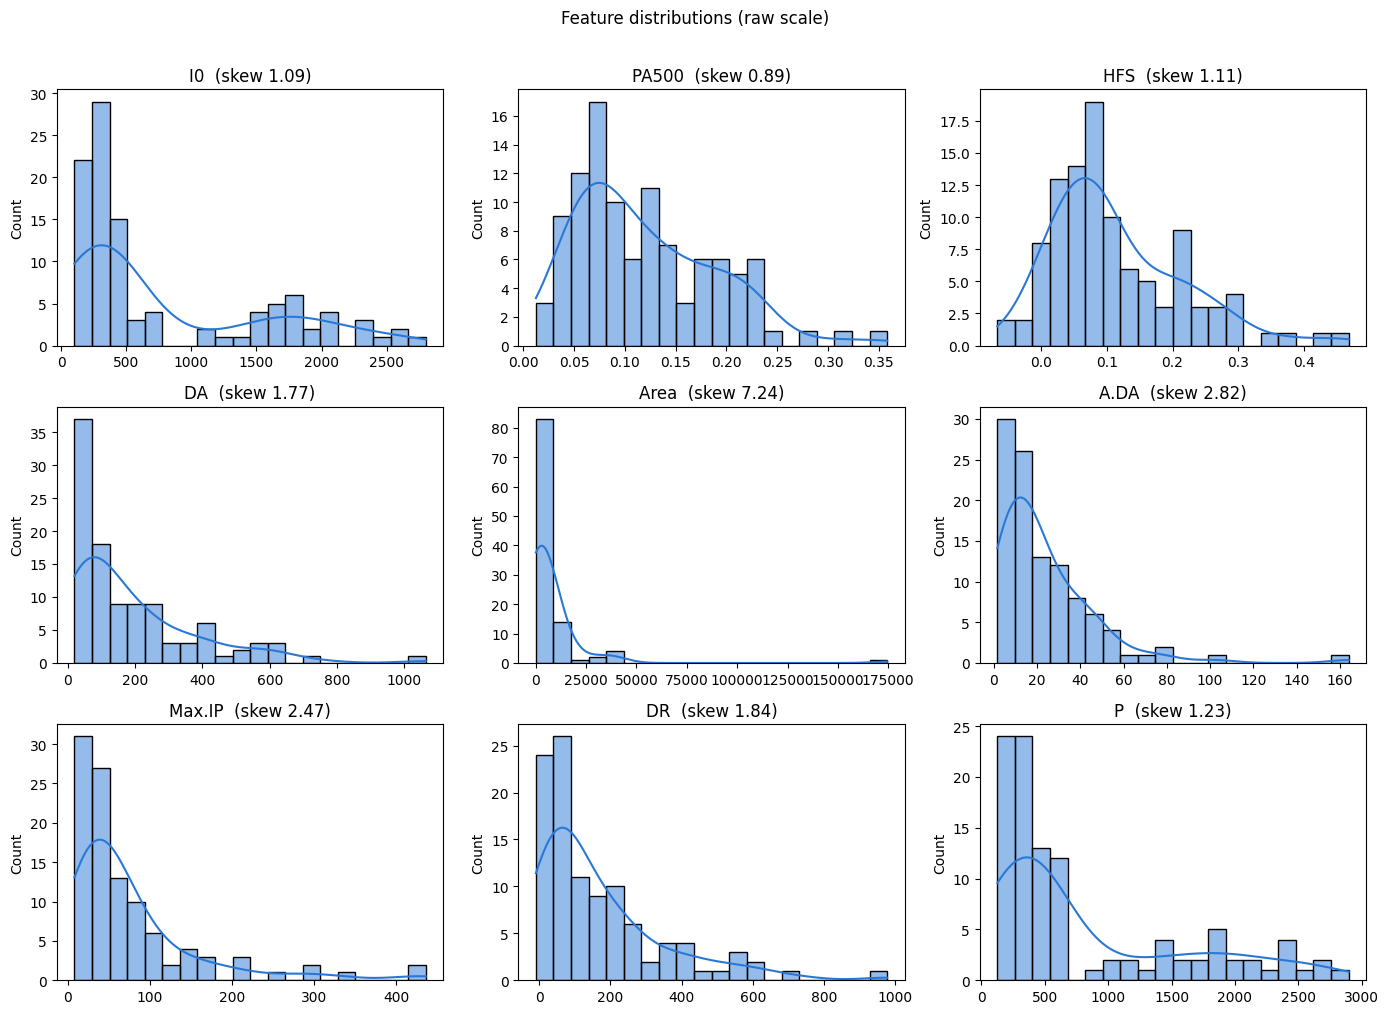

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, features):
    sns.histplot(df[col], bins=20, kde=True, ax=ax, color='#2a78d6')
    ax.set_title(f"{col}  (skew {df[col].skew():.2f})")
    ax.set_xlabel(None)
fig.suptitle('Feature distributions (raw scale)', y=1.01)
plt.tight_layout()
plt.show()

## Transform for Skew

Some models are scale sensitive and need to have features scaled. Heavy right tails suggest a log or Yeo-Johnson transform for scale-sensitive models.

Further Reading
- https://feature-engine.trainindata.com/en/1.8.x/user_guide/transformation/YeoJohnsonTransformer.html

In [0]:
from sklearn.preprocessing import PowerTransformer

yj = pd.DataFrame(PowerTransformer(method='yeo-johnson').fit_transform(df[features]), columns=features)

skew_compare = pd.DataFrame({'raw skew': df[features].skew(), 'Yeo-Johnson skew': yj.skew()}).round(2)
display(skew_compare.reset_index(names='feature'))

feature,raw skew,Yeo-Johnson skew
I0,1.09,0.11
PA500,0.89,0.11
HFS,1.11,0.05
DA,1.77,0.01
Area,7.24,-0.0
A.DA,2.82,-0.0
Max.IP,2.47,0.03
DR,1.84,0.25
P,1.23,0.1


## Outliers

Interquartile Range (IQR) 

IQR rule (beyond 1.5 × IQR from the quartiles). On skewed features, "outliers" are often just the long tail of a real class, so check which class they belong to before removing anything.

Further Reading
- https://www.jmp.com/en/statistics-knowledge-portal/exploratory-data-analysis/descriptive-statistics/interquartile-range

In [0]:
q1, q3 = df[features].quantile(0.25), df[features].quantile(0.75)
iqr = q3 - q1
is_outlier = (df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)

outlier_counts = is_outlier.sum().rename('outliers').to_frame()
outlier_counts['percent'] = (outlier_counts['outliers'] / len(df) * 100).round(1)
display(outlier_counts.reset_index(names='feature'))

# Which classes do the outliers come from?
outliers_by_class = is_outlier.groupby(df['ClassName'], observed=False).sum()
display(outliers_by_class.reset_index())

feature,outliers,percent
I0,0,0.0
PA500,1,1.0
HFS,4,3.8
DA,7,6.7
Area,8,7.6
A.DA,5,4.8
Max.IP,10,9.5
DR,7,6.7
P,0,0.0


ClassName,I0,PA500,HFS,DA,Area,A.DA,Max.IP,DR,P
Carcinoma,0,1,1,0,0,0,0,0,0
Fibro-adenoma,0,0,0,0,0,0,0,0,0
Mastopathy,0,0,1,0,0,0,0,0,0
Glandular,0,0,0,0,0,0,0,0,0
Connective,0,0,0,3,0,0,0,4,0
Adipose,0,0,2,4,8,5,10,3,0


## Features by class

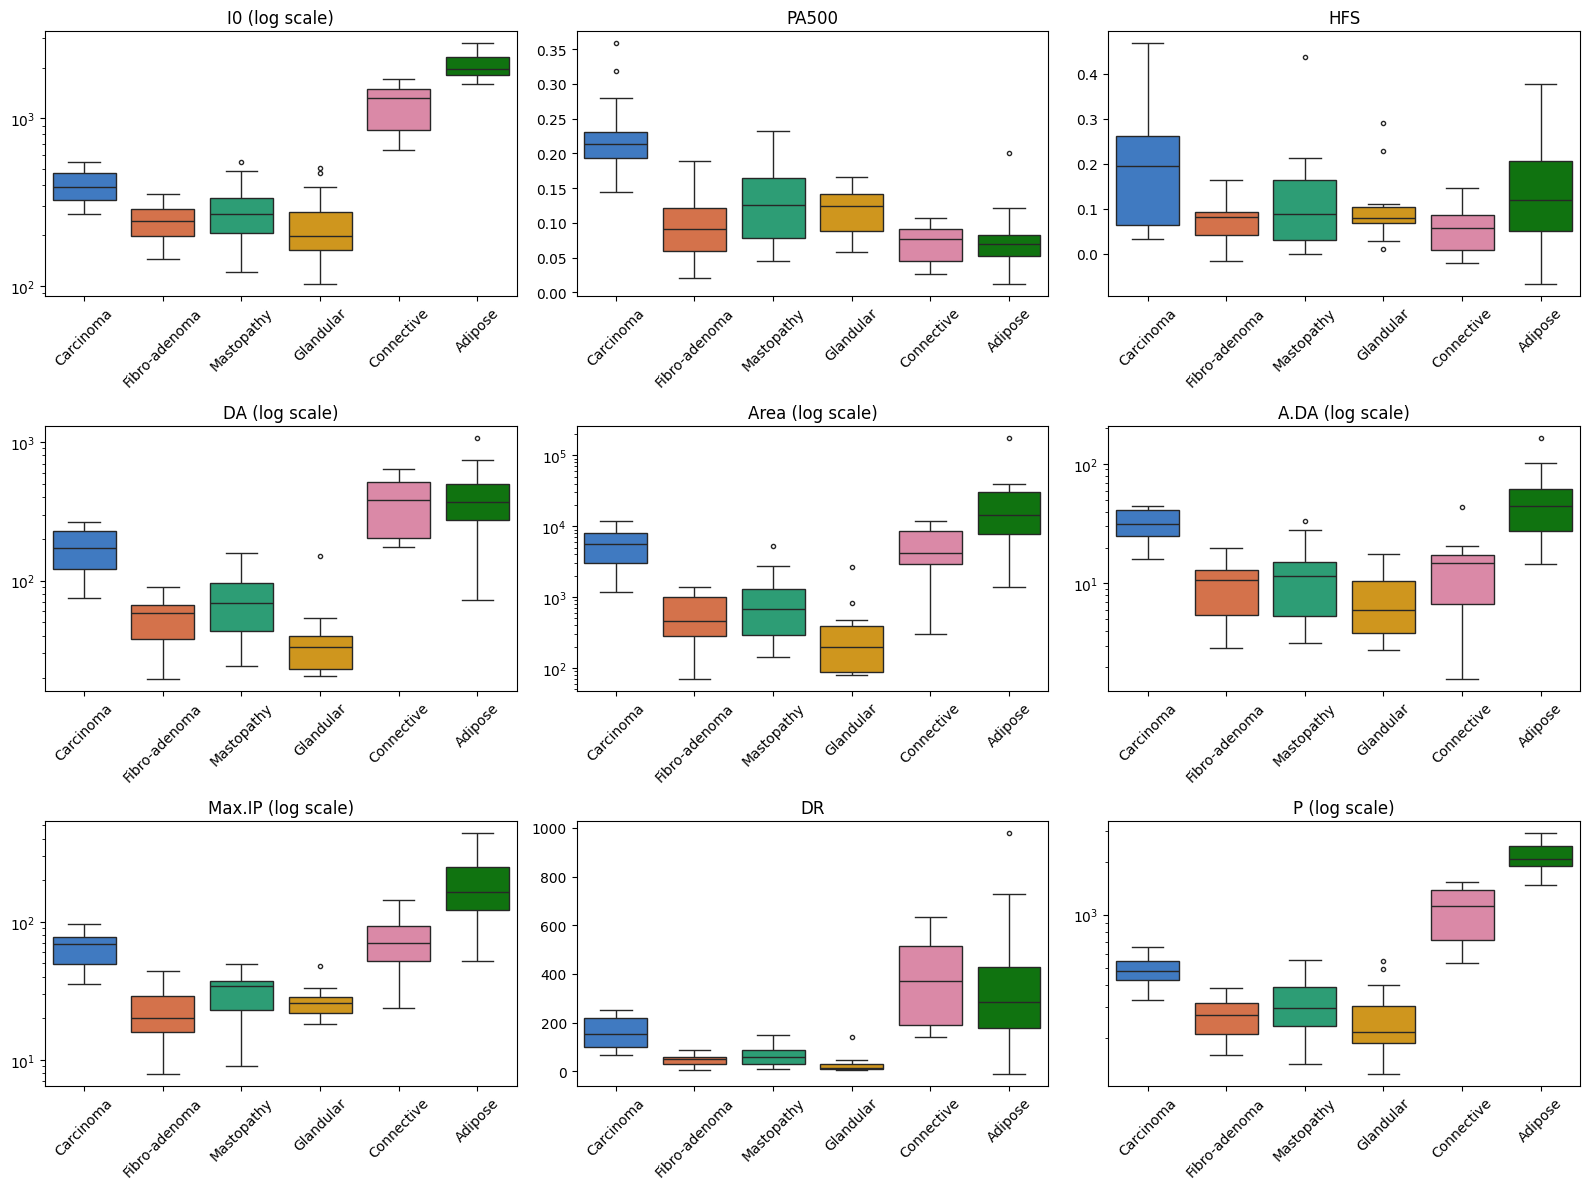

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

log_features = [c for c in features if (df[c] > 0).all() and df[c].skew() > 1]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, features):
    sns.boxplot(data=df, x='ClassName', y=col, hue='ClassName', palette=class_colors,
                order=class_order, legend=False, ax=ax, linewidth=1, fliersize=3)
    if col in log_features:
        ax.set_yscale('log')
        ax.set_title(f"{col} (log scale)")
    else:
        ax.set_title(col)
    ax.set_xlabel(None)
    ax.set_ylabel(None)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## Class medians

In [0]:
class_medians = df.groupby('ClassName', observed=False)[features].median()
display(class_medians.round(2).reset_index())

ClassName,I0,PA500,HFS,DA,Area,A.DA,Max.IP,DR,P
Carcinoma,389.87,0.21,0.19,172.37,5541.26,31.3,69.39,153.17,477.55
Fibro-adenoma,245.0,0.09,0.08,58.24,465.09,10.66,20.09,52.79,267.52
Mastopathy,267.64,0.13,0.09,68.68,668.53,11.53,34.04,59.4,294.23
Glandular,197.0,0.12,0.08,33.46,197.01,5.95,25.92,13.96,215.37
Connective,1328.17,0.08,0.06,381.04,4186.21,14.77,70.1,372.05,1121.19
Adipose,1974.56,0.07,0.12,370.06,14426.64,44.59,164.63,286.92,2068.05


## Feature Separation

The Kruskal-Wallis H test is a non-parametric statistical test used to compare three or more independent groups to see if they come from the same distribution or have equal medians. It serves as the rank-based alternative to one-way ANOVA when data are ordinal or non-normally distributed.

Further Reading
- https://en.wikipedia.org/wiki/Kruskal%E2%80%93Wallis_test

In [0]:
from scipy import stats

rows = []
for col in features:
    groups = [g[col].values for _, g in df.groupby('ClassName', observed=False)]
    h, p = stats.kruskal(*groups)
    rows.append({'feature': col, 'H': h, 'p_value': p, 'epsilon_sq': h / (len(df) - 1)})

separability = pd.DataFrame(rows).sort_values('H', ascending=False).reset_index(drop=True)
display(separability.round({'H': 1, 'epsilon_sq': 3}))

top_features = separability['feature'].head(4).tolist()
print(f"Most separating features: {top_features}")

feature,H,p_value,epsilon_sq
P,85.8,5.190759701394258E-17,0.825
I0,82.8,2.229201305349846E-16,0.796
DA,81.1,4.981077534936035E-16,0.78
Max.IP,78.3,1.922780751061956E-15,0.753
Area,75.0,9.23856790849095E-15,0.721
DR,69.5,1.2973051732650087E-13,0.668
A.DA,67.6,3.1667675599349794E-13,0.65
PA500,56.3,6.923121457350261E-11,0.542
HFS,17.2,0.004128541364441752,0.165


Most separating features: ['P', 'I0', 'DA', 'Max.IP']


## Pairwise Plot

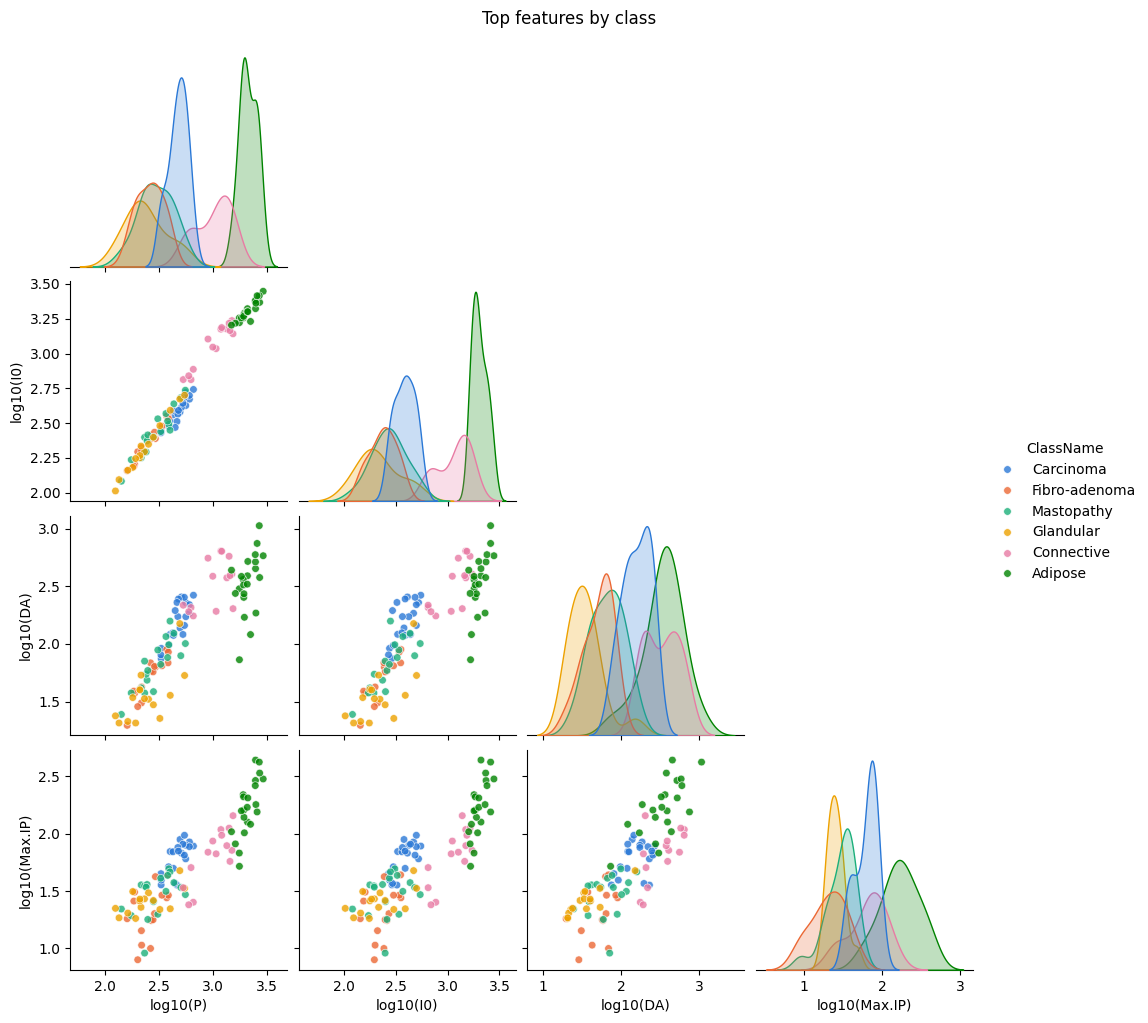

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

pair_df = df[['ClassName']].copy()
pair_vars = []
for col in top_features:
    name = f"log10({col})" if col in log_features else col
    pair_df[name] = np.log10(df[col]) if col in log_features else df[col]
    pair_vars.append(name)

g = sns.pairplot(
    pair_df, vars=pair_vars, hue='ClassName', hue_order=class_order, palette=class_colors,
    corner=True, plot_kws={'s': 30, 'alpha': 0.8, 'edgecolor': 'white', 'linewidth': 0.5},
)
g.figure.suptitle('Top features by class', y=1.02)
plt.show()

In [0]:
fig = px.scatter(
    df, x=top_features[0], y=top_features[1], color='ClassName',
    color_discrete_map=class_colors, category_orders={'ClassName': class_order},
    log_x=top_features[0] in log_features, log_y=top_features[1] in log_features,
    hover_data=features, title=f"{top_features[0]} vs {top_features[1]}",
)
fig.update_traces(marker=dict(size=9, line=dict(width=1, color='white')))
fig.show()

<!doctype html>

# Principal Component Analysis

Check how redundant the features are. 

Further Reading
- https://en.wikipedia.org/wiki/Principal_component_analysis

In [0]:
from sklearn.decomposition import PCA

pca = PCA(random_state=RANDOM_STATE)
pcs = pca.fit_transform(yj)

explained = pd.DataFrame({
    'component': [f"PC{i+1}" for i in range(len(features))],
    'explained_variance': pca.explained_variance_ratio_,
    'cumulative': pca.explained_variance_ratio_.cumsum(),
})
display(explained.round(3))

pca_df = pd.DataFrame(pcs[:, :2], columns=['PC1', 'PC2'])
pca_df['ClassName'] = df['ClassName'].values
pca_df['Class4'] = df['Class4'].values

fig = px.scatter(
    pca_df, x='PC1', y='PC2', color='ClassName', color_discrete_map=class_colors,
    category_orders={'ClassName': class_order},
    title=f"PCA (6 classes) — PC1+PC2 explain {explained['cumulative'][1]:.0%} of variance",
)
fig.update_traces(marker=dict(size=9, line=dict(width=1, color='white')))
fig.show()

# COMMAND ----------

# What drives each component?
loadings = pd.DataFrame(pca.components_[:2].T, index=features, columns=['PC1', 'PC2'])
display(loadings.round(3).reset_index(names='feature'))

component,explained_variance,cumulative
PC1,0.645,0.645
PC2,0.209,0.854
PC3,0.066,0.92
PC4,0.056,0.976
PC5,0.015,0.991
PC6,0.006,0.998
PC7,0.002,1.0
PC8,0.0,1.0
PC9,0.0,1.0


<!doctype html>

feature,PC1,PC2
I0,0.382,-0.255
PA500,-0.018,0.659
HFS,0.06,0.575
DA,0.397,-0.062
Area,0.403,0.125
A.DA,0.338,0.296
Max.IP,0.385,0.143
DR,0.336,-0.103
P,0.393,-0.181


## Adjusting based on study observations

The dataset authors note that fibro-adenoma, mastopathy and glandular are hard to tell apart. Merging them gives a 4-class problem.

In [0]:
display(df['Class4'].value_counts().reindex(class4_order).rename('count').reset_index())

fig = px.scatter(
    pca_df, x='PC1', y='PC2', color='Class4', color_discrete_map=class4_colors,
    category_orders={'Class4': class4_order}, title='PCA (4 classes)',
)
fig.update_traces(marker=dict(size=9, line=dict(width=1, color='white')))
fig.show()

Class4,count
Carcinoma,21
Fad+Mas+Gla,48
Connective,14
Adipose,22


<!doctype html>

# Modeling

## Set Up

There isn't enough data to withhold a test dataset so we use k-folds to validate the data. We'll compare different models against a baseline.

Terms
- RepeatedStratifiedKFold is a cross-validation technique in machine learning that combines stratified k-fold sampling with repeated trials. It is designed primarily for classification problems, especially those involving imbalanced datasets.
- Logistic regression is a statistical and machine learning method used for classification. It predicts the probability of a categorical outcome—such as yes or no—by passing a linear combination of input features through a sigmoid (logistic) function.
- The k-nearest neighbors (KNN) algorithm is a non-parametric, supervised machine learning method used for classification and regression. It predicts the label or value of a new data point by looking at the k closest training examples in feature space.
- A support vector machine (SVM) is a supervised machine learning model used for classification, regression, and outlier detection by finding an optimal boundary—called a hyperplane—that maximizes the margin between classes.
- A Random Forest Classifier is a supervised machine learning algorithm that builds an ensemble of multiple decision trees and merges their predictions—typically through majority voting—to produce a more accurate and stable classification.

Further Reading
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html
- https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html
- https://scikit-learn.org/stable/auto_examples/svm/plot_rbf_parameters.html#sphx-glr-auto-examples-svm-plot-rbf-parameters-py
- https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html


In [0]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    RepeatedStratifiedKFold
)

X = df[features]
y6 = df['ClassName'].astype(str)
y4 = df['Class4'].astype(str)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
scoring = ['accuracy', 'f1_macro']

models = {
    'Baseline (most frequent)': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_pipeline(PowerTransformer(), LogisticRegression(max_iter=2000, C=1.0)),
    'k-NN (k=5)': make_pipeline(PowerTransformer(), KNeighborsClassifier(n_neighbors=5)),
    'SVM (RBF)': make_pipeline(PowerTransformer(), SVC(C=10, gamma='scale')),
    'Random forest': RandomForestClassifier(n_estimators=500, min_samples_leaf=2, random_state=RANDOM_STATE),
}

## Model Comparisson

Cross-validation (CV) is a resampling technique used in machine learning to evaluate how well a model generalizes to unseen data and to prevent overfitting. Instead of relying on a single split of your dataset, it repeatedly divides the data into subsets—training the model on some parts and testing it on the remaining parts—to produce a more reliable performance estimate.

Further Reading
- https://en.wikipedia.org/wiki/Cross-validation_(statistics)

In [0]:
from sklearn.model_selection import (
    cross_validate
)

results = []
for target_name, y in [('6 classes', y6), ('4 classes', y4)]:
    for name, model in models.items():
        res = cross_validate(model, X, y, cv=cv, scoring=scoring)
        results.append({
            'target': target_name,
            'model': name,
            'accuracy_mean': res['test_accuracy'].mean(),
            'accuracy_std': res['test_accuracy'].std(),
            'f1_macro_mean': res['test_f1_macro'].mean(),
            'f1_macro_std': res['test_f1_macro'].std(),
        })

results_df = pd.DataFrame(results)
display(results_df.round(3))

target,model,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std
6 classes,Baseline (most frequent),0.21,0.023,0.058,0.005
6 classes,Logistic regression,0.694,0.084,0.666,0.09
6 classes,k-NN (k=5),0.64,0.086,0.596,0.087
6 classes,SVM (RBF),0.708,0.08,0.682,0.088
6 classes,Random forest,0.686,0.092,0.653,0.104
4 classes,Baseline (most frequent),0.457,0.023,0.157,0.006
4 classes,Logistic regression,0.91,0.052,0.902,0.061
4 classes,k-NN (k=5),0.87,0.059,0.838,0.076
4 classes,SVM (RBF),0.887,0.05,0.874,0.061
4 classes,Random forest,0.898,0.054,0.881,0.065


In [0]:
import plotly.express as px

fig = px.bar(
    results_df, x='model', y='f1_macro_mean', error_y='f1_macro_std', color='target', barmode='group',
    color_discrete_map={'6 classes': '#2a78d6', '4 classes': '#eb6834'},
    title='Macro F1 by model (mean ± std over 50 CV folds)',
)
fig.update_layout(xaxis_title=None, yaxis_title='Macro F1', yaxis_range=[0, 1])
fig.show()

<!doctype html>

## Confusion Matrix

A confusion matrix (or error matrix) is a table that compares actual outcomes against predicted outcomes to evaluate how well a classification model or person performs. It shows both right and wrong predictions for each class, making specific error patterns easy to spot.

- True Positive (TP): Actual is positive; predicted is positive.
- True Negative (TN): Actual is negative; predicted is negative.
- False Positive (FP / Type I Error): Actual is negative; predicted is positive.
- False Negative (FN / Type II Error): Actual is positive; predicted is negative.

Derrived metrics
- Accuracy: \(\frac{TP+TN}{TP+TN+FP+FN}\) - Overall share of correct predictions. Can look high even when rare classes are missed.
- Precision: \(\frac{TP}{TP+FP}\) - Share of predicted positives that are actually positive.
- Recall (Sensitivity): \(\frac{TP}{TP+FN}\) - Share of actual positives that the model caught.
- F1 Score: \(2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}\) - Balance between precision and recall.

Further Reading
- https://en.wikipedia.org/wiki/Confusion_matrix
- https://www.dataschool.io/simple-guide-to-confusion-matrix-terminology/



Best 4-class model by macro F1: Logistic regression


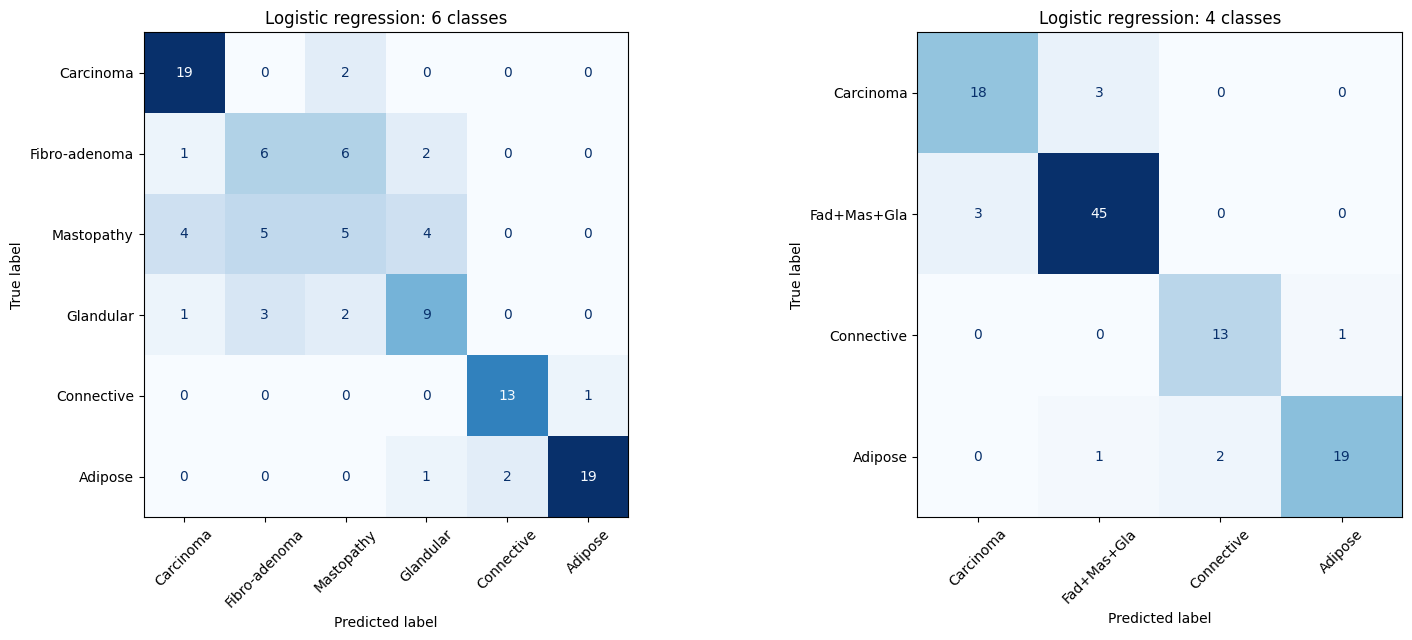

               precision    recall  f1-score   support

    Carcinoma       0.76      0.90      0.83        21
Fibro-adenoma       0.43      0.40      0.41        15
   Mastopathy       0.33      0.28      0.30        18
    Glandular       0.56      0.60      0.58        15
   Connective       0.87      0.93      0.90        14
      Adipose       0.95      0.86      0.90        22

     accuracy                           0.68       105
    macro avg       0.65      0.66      0.65       105
 weighted avg       0.67      0.68      0.67       105



In [0]:
from sklearn.model_selection import (
    StratifiedKFold, cross_val_predict,
)
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best_name = (
    results_df[results_df['target'] == '4 classes']
    .sort_values('f1_macro_mean', ascending=False)['model'].iloc[0]
)
best_model = models[best_name]
print(f"Best 4-class model by macro F1: {best_name}")

cv_single = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (title, y, order) in zip(axes, [('6 classes', y6, class_order), ('4 classes', y4, class4_order)]):
    pred = cross_val_predict(best_model, X, y, cv=cv_single)
    ConfusionMatrixDisplay.from_predictions(y, pred, labels=order, cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f"{best_name}: {title}")
    ax.tick_params(axis='x', rotation=45)
    ax.grid(False)
plt.tight_layout()
plt.show()

pred6 = cross_val_predict(best_model, X, y6, cv=cv_single)
print(classification_report(y6, pred6, labels=class_order))

## ML Flow Experiment Tracking

In [0]:
import mlflow

with mlflow.start_run(run_name='breast_tissue_model_comparison'):
    mlflow.log_param('cv', '5-fold stratified x 10 repeats')
    mlflow.log_param('n_rows', len(df))
    for row in results_df.itertuples():
        with mlflow.start_run(run_name=f"{row.model} | {row.target}", nested=True):
            mlflow.log_params({'model': row.model, 'target': row.target})
            mlflow.log_metrics({
                'accuracy_mean': row.accuracy_mean,
                'accuracy_std': row.accuracy_std,
                'f1_macro_mean': row.f1_macro_mean,
                'f1_macro_std': row.f1_macro_std,
            })

# Commentary

Mathematically all of the models do much better than the baseline, but there are clinical concerns about the results. While recall is 90% on the best 4 class model, only 3/4 of predictions are correct. Half of the wrong predictions indicated carcinoma instead of healthy tissue, potentially causing unnecesary, painful repeat biopsies to confirm the diagnosis. The other half of the wrong predictions indicated healthy tissue when carcinoma was present, preventing early intervention.

## Limitations

- Small sample size
- Redundant data, just two features account for 85% of the variance
- One lab and one measurement source

## Expansion ideas

- Experiment with a binary classification model (carcinoma or not carcinoma)
- Experiment with just top features
- Repeat with more data
- Register the chosen model in Unity Catalog via MLflow for reproducibility.